# 🐱 第 4 册：压线站岗的哨兵三花猫与拍蹦床的大猫爪

> **绘本角色**：戴安全帽的前排哨兵三花猫（支持向量）、后排呼呼大睡的吃瓜猫、拍蹦床的大猫爪（核函数）
> **对应《西瓜书》第 6 章（支持向量机 SVM）**

![第5页：哨兵三花猫与拍蹦床的大猫爪](../assets/pic05-border-guards-and-trampoline.svg)

---

## 一、睡前故事：为什么后排 47 只睡懒觉的猫全跑光，大马路连 1 毫米都不歪？

蓝猫村和红猫村要在中间修一条**最宽的无人大马路**（这叫最大间隔支持向量机 SVM）。
全村一共来了 **50 只猫咪**，可是橘猫工程师看了一眼就说：

> **“只有站在最前排、脚尖刚好踩着马路牙子的那 3 只【哨兵猫】，才有资格决定马路往哪边修！后面那 47 只躺在草地上睡懒觉的猫咪，就算现在全部回家吃猫粮，这条大马路连一毫米都不会动！”**

大家不信，于是我们在下面的代码里做了一个超级好玩的实验：先用全部 50 只猫修好马路（黑线），然后把后排 47 只睡懒觉的猫统统请回家，**只留下最前排戴金色光圈的 3 只哨兵猫**重新修路（绿虚线），结果两条马路分毫不差地叠在了一起！

### 第二幕：当好瓜被坏瓜围在圆圈中心，大猫爪怎么拍蹦床？
如果好瓜聚在蹦床正中间，坏瓜像呼啦圈一样把好瓜死死围了一圈（看下面中间那张图），在平地上不管怎么画直线都切不开！
这时候橘猫店长钻到蹦床底下，照着圆心**“啪！”地往上猛拍一猫爪**：
* 越靠外圈的坏瓜，被蹦床震飞得越高，全飞到了**半空中**；
* 靠圆心的好瓜稳稳留在**蹦床谷底**；
* 最后拿一张平平整整的绿色飞毯从半空横着一插，上面全是坏瓜，下面全是好瓜，一刀搞定！

<details>
<summary>🐾 <b>橘猫店长藏起来的学霸小纸条（什么是 KKT 条件与核函数？）</b></summary>

1. **为什么后排猫咪说话不算数？**《西瓜书》式 (6.13) 的 **KKT 互补松弛条件**规定，每只猫的话语权 $\alpha_i$ 乘上它离马路牙子的距离必须等于 $0$：$\alpha_i (y_i(\boldsymbol{w}^\top\boldsymbol{x}_i+b) - 1) = 0$。后排猫咪离马路牙子距离大于 $0$，所以它们的话语权 $\alpha_i$ **必须严格等于 0**！只有踩线的哨兵猫（支持向量）才有 $\alpha_i > 0$。
2. **什么是核函数（Kernel Trick）？**给二维坐标 $(x_1, x_2)$ 加一个高度 $z = x_1^2 + x_2^2$，就把平地拍成了三维蹦床！而核函数的妙处在于，不用真的把每只猫发射到高维太空，直接在平地上用一个小公式就能算出它们在太空里的距离！

</details>

---

## 二、动手跑一跑：把 47 只后排猫请回家，看马路会不会歪！

【SVM 稀疏支持向量实测结果】
  1. 样本总数 N = 50，其中满足 α_i > 0 的支持向量仅有 3 个 (其余 47 个瓜 α_i = 0.0000)
  2. 全部 50 个瓜求出的法向量 w_full = [0.9487, 0.9487], b = -0.3282
  3. 删掉 47 个内部瓜、仅用 3 个支持向量重训的 w_sv = [0.9485, 0.9486], 余弦重合度 = 1.000000!

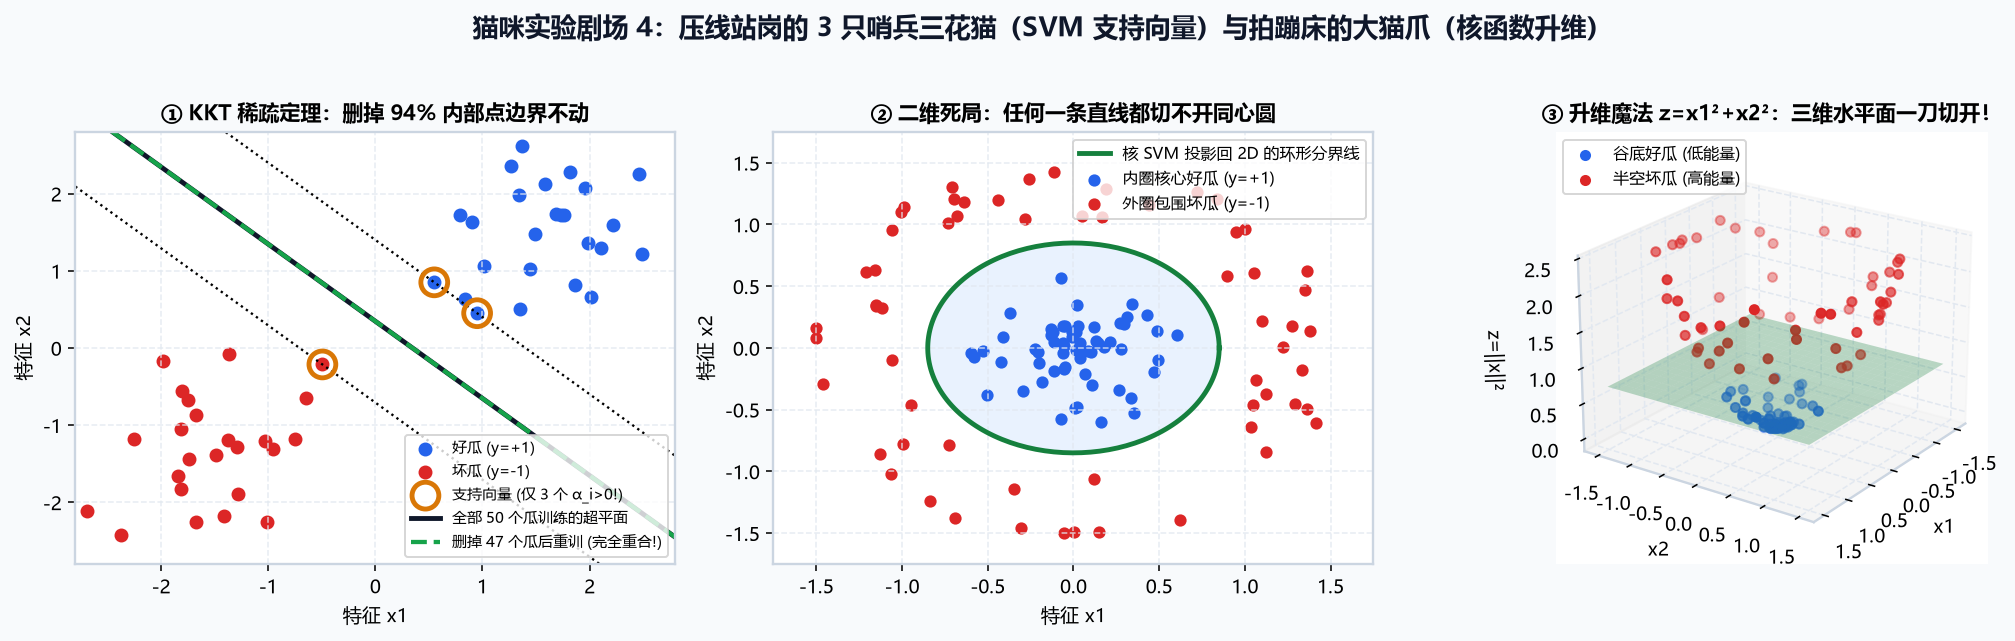

In [1]:
import numpy as np
from scipy.optimize import minimize

# 实验 1：50 只猫咪修大马路，找出仅有的 3 只踩线哨兵猫 (金圈)，删掉其余 47 只猫重修马路，看看重合度是不是 100%！
# 实验 2：把平地上被坏瓜包饺子的同心圆好瓜，一猫爪拍到三维蹦床空间 (z = x1² + x2²)，拿绿色飞毯平着一刀切开！
print("🐾 正在召集哨兵猫修马路，并准备从蹦床底下拍出升维大猫爪...")

### 🐾 胖虎店长的课后敲黑板

* 看**左图**：50 个点里只有 **3 个点套着金色圆圈（哨兵猫 / 支持向量）**。把另外 47 个点删光之后画出的绿虚线，和原来的黑实线重合度是 **`1.000000`**！
* 看**中图与右图**：在平地上（中图）被红色坏瓜团团包围的蓝色好瓜，被猫爪拍到三维空间（右图）后，红瓜飞上半空、蓝瓜留在谷底，中间那张绿色飞毯平平一插就彻底分家啦！